In [ ]:
import pandas as pd

# Option: Load directly from your GitHub raw link
url = "https://raw.githubusercontent.com/243Christian/DATA110/main/vgsales.csv"
df = pd.read_csv(url)

# 1. Basic Structure & Shape
print("Dataset Shape:", df.shape)
print("\n--- Column Info ---")
print(df.info())

# 2. Handle Missing Values
df_clean = df.dropna(subset=["Year", "Publisher"]).copy()
print(f"\nRows after dropping missing years/publishers: {df_clean.shape[0]}")

# 3. Summary Statistics for Sales
print("\n--- Global Sales Summary Statistics ---")
print(df_clean["Global_Sales"].describe())

Dataset Shape: (16598, 11)

--- Column Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB
None

Rows after dropping missing years/publishers: 16291

--- Global Sales Summary Statistics ---
count    16291.000000
mean         0.540910
std          1.567345
min          0.010000
25%          0.060000
50%          

/tmp/ipykernel_2987/2739725161.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


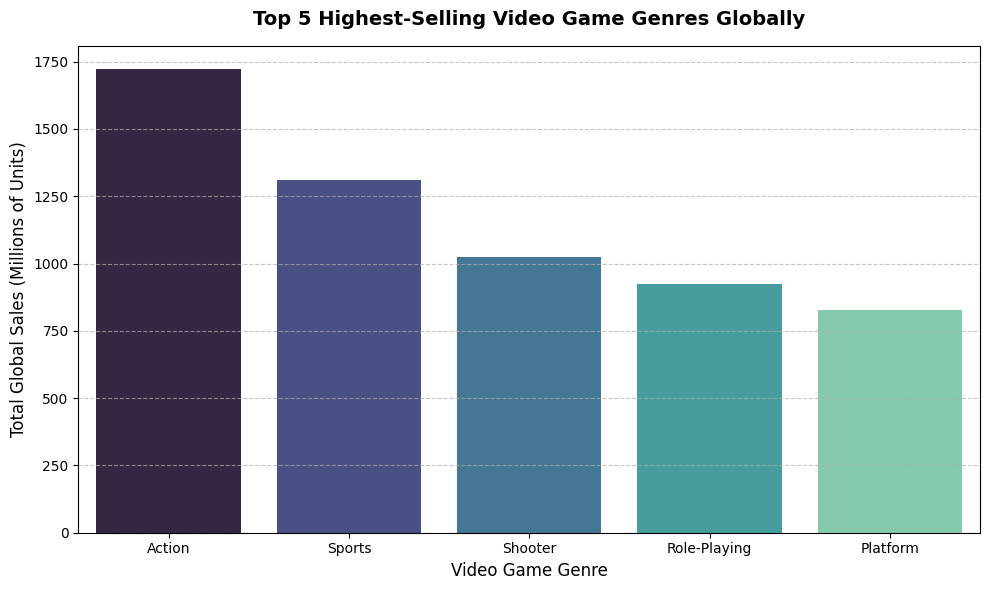

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group by Genre and sum global sales, then grab top 5
genre_sales = df_clean.groupby("Genre")["Global_Sales"].sum().reset_index()
genre_sales = genre_sales.sort_values(by="Global_Sales", ascending=False).head(5)

# Set up the plot style
plt.figure(figsize=(10, 6))
sns.barplot(
    data=genre_sales,
    x="Genre",
    y="Global_Sales",
    palette="mako"
)

# Add title, labels, and clean design
plt.title("Top 5 Highest-Selling Video Game Genres Globally", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Video Game Genre", fontsize=12)
plt.ylabel("Total Global Sales (Millions of Units)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Show plot
plt.tight_layout()
plt.show()

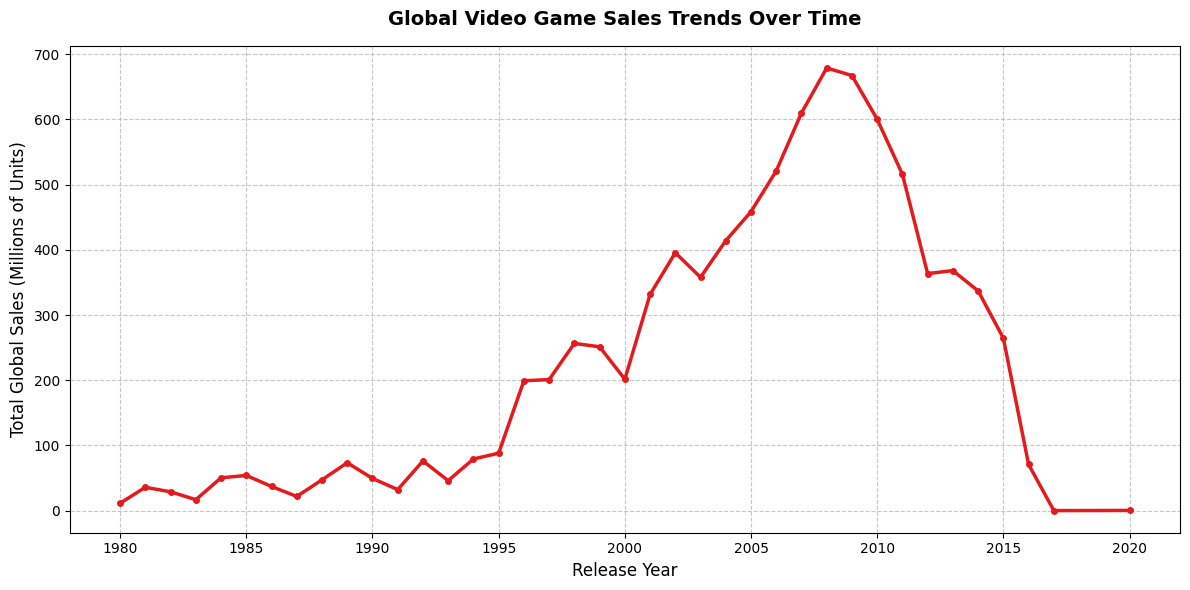

In [ ]:
# Group by Year and sum global sales
yearly_sales = df_clean.groupby("Year")["Global_Sales"].sum().reset_index()

# Set up the plot style
plt.figure(figsize=(12, 6))
plt.plot(
    yearly_sales["Year"],
    yearly_sales["Global_Sales"],
    color="#e41a1c",
    linewidth=2.5,
    marker="o",
    markersize=4
)

# Add title, labels, and clean design
plt.title("Global Video Game Sales Trends Over Time", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Release Year", fontsize=12)
plt.ylabel("Total Global Sales (Millions of Units)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.7)

# Show plot
plt.tight_layout()
plt.show()

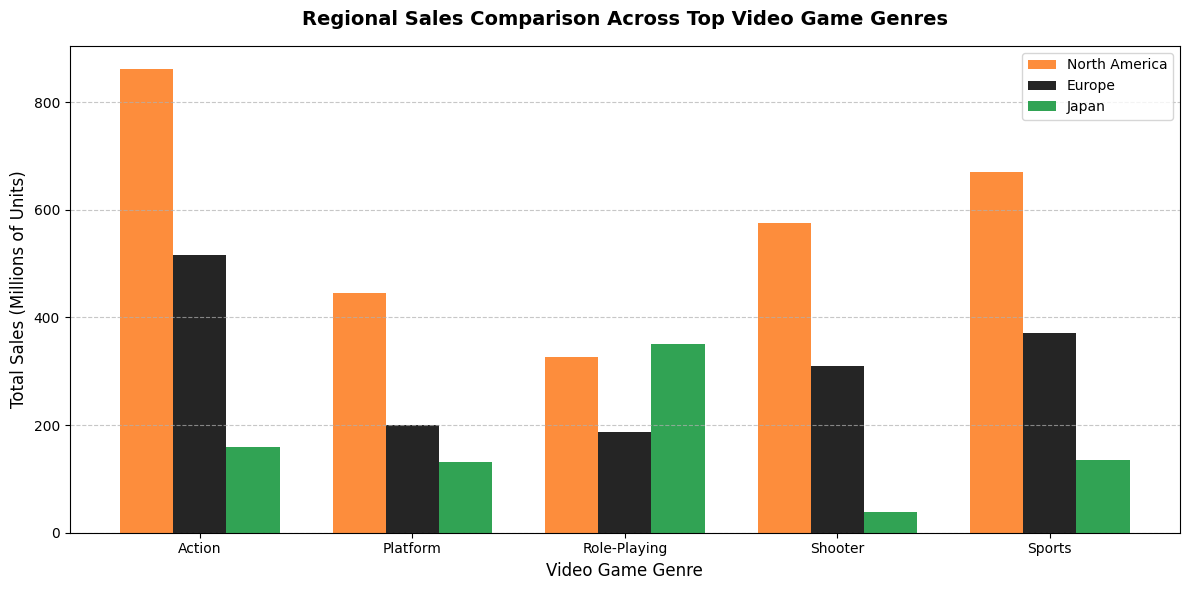

In [ ]:
import numpy as np

# Group by Genre and sum regional sales for top 5 genres
top_genres = genre_sales["Genre"].tolist()
region_sales = df_clean[df_clean["Genre"].isin(top_genres)].groupby("Genre")[["NA_Sales", "EU_Sales", "JP_Sales"]].sum().reset_index()

# Set up bar positions
x = np.arange(len(region_sales["Genre"]))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(x - width, region_sales["NA_Sales"], width, label="North America", color="#fd8d3c") # Orange
plt.bar(x, region_sales["EU_Sales"], width, label="Europe", color="#252525")          # Black
plt.bar(x + width, region_sales["JP_Sales"], width, label="Japan", color="#31a354")          # Green

plt.title("Regional Sales Comparison Across Top Video Game Genres", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Video Game Genre", fontsize=12)
plt.ylabel("Total Sales (Millions of Units)", fontsize=12)
plt.xticks(x, region_sales["Genre"])
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()